# Deepfake Detection: Testing, Evaluation & Inference

Comprehensive evaluation and inference notebook for the trained Deepfake Detection model:
1. **Centralized Configuration**: All test settings and parameters defined in one block.
2. **Zero Resize Overhead**: Evaluates directly on native 256x256 test images.
3. **High-Throughput Evaluation**: Batch size 256 and 4 CPU workers for fast test set benchmarking.
4. **Model Loader**: Standalone loader supporting `deepfake_detection_model.pth`, `checkpoints/best_model.pth`, and serialized `.pt` models.
5. **Independent Test Metrics**: Full evaluation on the untouched 20,000-image test set (Accuracy, Loss, Precision, Recall, F1).
6. **Confusion Matrix Heatmap**: Visual heatmap of True/False Positives & Negatives.
7. **Single & Batch Inference Visualizers**: Interactive predictions with confidence scores and probability bars.

In [1]:
# ==============================================================================
# ðŸŽ¯ CENTRALIZED TESTING CONFIGURATION & IMPORTS
# ==============================================================================
import os
import glob
import math
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Set device and hardware acceleration
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 60)
print("PyTorch Version:", torch.__version__)
print("Active Device:  ", device)
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    total_mem = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"GPU Hardware:   {gpu_name} ({total_mem:.2f} GB VRAM)")
print("=" * 60)

# Dataset Path & Model Loading Settings
DATASET_PATH = r"C:\Users\MADHUSHALNE\DATASET ML\140K Real and Fake Faces dataset\real_vs_fake\real-vs-fake"
IMG_SIZE = 256                     # Native 256x256 resolution (No resizing needed)
BATCH_SIZE = 256                   # Batch size 256 for fast evaluation throughput
NUM_WORKERS = 4                    # 4 CPU workers
MODEL_PATH = "deepfake_detection_model.pth" # Path to trained model package


PyTorch Version: 2.11.0+cu126
Active Device:   cuda
GPU Hardware:   NVIDIA GeForce RTX 3050 Ti Laptop GPU (4.00 GB VRAM)


## 1. Load Test Dataset & Prepare DataLoader (Zero Resize Overhead)
Loads the untouched test split (20,000 images: 10,000 real + 10,000 fake).

In [2]:
# Test transforms without resize overhead
test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_dir = os.path.join(DATASET_PATH, "test")
if os.path.exists(test_dir):
    test_dataset = datasets.ImageFolder(test_dir, transform=test_transforms)
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True if torch.cuda.is_available() else False,
        persistent_workers=True if NUM_WORKERS > 0 else False,
        prefetch_factor=2 if NUM_WORKERS > 0 else None
    )
    print(f"Test Dataset Loaded: {len(test_dataset):,} total images ({len(test_loader)} batches at batch size {BATCH_SIZE})")
    print(f"Classes: {test_dataset.classes} -> {test_dataset.class_to_idx}")
else:
    print(f"[!] Test dataset directory not found at: {test_dir}")
    test_dataset = []
    test_loader = []


Test Dataset Loaded: 20,000 total images (79 batches at batch size 256)
Classes: ['fake', 'real'] -> {'fake': 0, 'real': 1}


## 2. Load Trained Deepfake Detection Model
Loads the model weights from `deepfake_detection_model.pth` or fallback checkpoints.

In [3]:
def load_trained_deepfake_model(model_path=MODEL_PATH, device=None):
    """
    Loads the trained Deepfake Detection model from disk.
    Works independently in any Python session.
    """
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        
    # Check primary path and fallback checkpoints
    if not os.path.exists(model_path):
        fallbacks = [
            os.path.join("checkpoints", "best_model.pth"),
            os.path.join("checkpoints", "last_checkpoint.pth"),
            "deepfake_detector_entire_model.pt"
        ]
        found = False
        for fb in fallbacks:
            if os.path.exists(fb):
                print(f"[i] '{model_path}' not found, using fallback: '{fb}'")
                model_path = fb
                found = True
                break
        if not found:
            raise FileNotFoundError(f"Model not found at '{model_path}' or any checkpoint folder. Train the model first!")
            
    print(f"Loading trained weights from: {model_path} onto {device}...")
    try:
        saved_data = torch.load(model_path, map_location=device, weights_only=False)
    except TypeError:
        saved_data = torch.load(model_path, map_location=device)
    
    # If saved as entire model instance
    if isinstance(saved_data, nn.Module):
        loaded_model = saved_data.to(device)
        loaded_model.eval()
        classes = ['fake', 'real']
        print(f"[+] Entire model loaded directly onto {device}.")
        return loaded_model, classes
        
    # If saved as state_dict / metadata package
    loaded_model = efficientnet_b0(weights=None)
    num_features = loaded_model.classifier[1].in_features
    loaded_model.classifier = nn.Sequential(
        nn.Dropout(p=0.3, inplace=True),
        nn.Linear(num_features, 2)
    )
    
    if isinstance(saved_data, dict) and 'model_state_dict' in saved_data:
        loaded_model.load_state_dict(saved_data['model_state_dict'])
        classes = saved_data.get('classes', ['fake', 'real'])
        val_acc = saved_data.get('val_acc', 0.0)
    elif isinstance(saved_data, dict):
        loaded_model.load_state_dict(saved_data)
        classes = ['fake', 'real']
        val_acc = 0.0
    else:
        loaded_model = saved_data
        classes = ['fake', 'real']
        val_acc = 0.0
        
    loaded_model = loaded_model.to(device)
    loaded_model.eval()
    
    print(f"[+] Model successfully loaded! (Saved Val Acc: {val_acc*100:.2f}%)")
    return loaded_model, classes

model, class_names = load_trained_deepfake_model(MODEL_PATH, device=device)


Loading trained weights from: deepfake_detection_model.pth onto cuda...
[+] Model successfully loaded! (Saved Val Acc: 98.29%)


## 3. Full Test Dataset Evaluation
Runs forward inference across all 20,000 test samples to compute Test Loss, Accuracy, and gather predictions.

In [4]:
if len(test_dataset) > 0:
    criterion = nn.CrossEntropyLoss()
    model.eval()

    test_loss = 0.0
    all_preds = []
    all_targets = []
    all_probs = []

    print("Evaluating test set...")
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                outputs = model(images)
                loss = criterion(outputs, labels)
                
            test_loss += loss.item() * images.size(0)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    test_loss = test_loss / len(test_dataset)
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    all_probs = np.array(all_probs)
    test_acc = np.mean(all_preds == all_targets)

    print(f"\n{'='*55}")
    print(f"FINAL TEST SET EVALUATION SUMMARY")
    print(f"{'='*55}")
    print(f"  Total Test Samples:  {len(test_dataset):,}")
    print(f"  Test Loss:           {test_loss:.4f}")
    print(f"  Test Accuracy:       {test_acc * 100:.2f}%")
    print(f"  Correct Predictions: {np.sum(all_preds == all_targets):,} / {len(test_dataset):,}")
    print(f"{'='*55}\n")
else:
    print("[!] Test dataset is empty or not loaded.")


Evaluating test set...


C:\Users\MADHUSHALNE\AppData\Local\Temp\ipykernel_26840\1824017560.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):



FINAL TEST SET EVALUATION SUMMARY
  Total Test Samples:  20,000
  Test Loss:           0.0486
  Test Accuracy:       98.11%
  Correct Predictions: 19,621 / 20,000



## 4. Confusion Matrix & Classification Report

Classification Report:
              precision    recall  f1-score   support

        fake     0.9688    0.9941    0.9813     10000
        real     0.9939    0.9680    0.9808     10000

    accuracy                         0.9810     20000
   macro avg     0.9814    0.9810    0.9810     20000
weighted avg     0.9814    0.9810    0.9810     20000



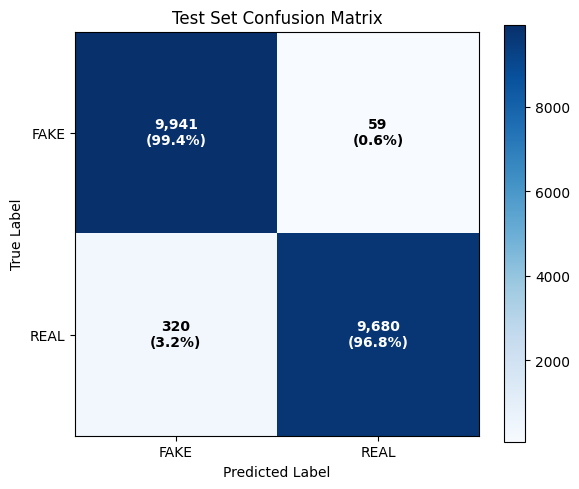

In [5]:
if 'all_preds' in globals() and len(all_preds) > 0:
    from sklearn.metrics import classification_report, confusion_matrix

    print("Classification Report:")
    print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

    cm = confusion_matrix(all_targets, all_preds)

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=[c.upper() for c in class_names],
        yticklabels=[c.upper() for c in class_names],
        title='Test Set Confusion Matrix',
        ylabel='True Label',
        xlabel='Predicted Label'
    )

    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        row_total = cm[i].sum()
        for j in range(cm.shape[1]):
            count = cm[i, j]
            pct = (count / row_total * 100) if row_total > 0 else 0.0
            ax.text(j, i, f"{count:,}\n({pct:.1f}%)",
                    ha="center", va="center",
                    color="white" if count > thresh else "black",
                    fontweight='bold')
    fig.tight_layout()
    plt.show()
else:
    print("[!] No test predictions available to display confusion matrix.")


## 5. Single Image Prediction Demo
Interactive helper function to test any individual image from disk and display predicted label, confidence, and probability distribution.

--- Testing Sample FAKE Face ---


C:\Users\MADHUSHALNE\AppData\Local\Temp\ipykernel_26840\3134179840.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


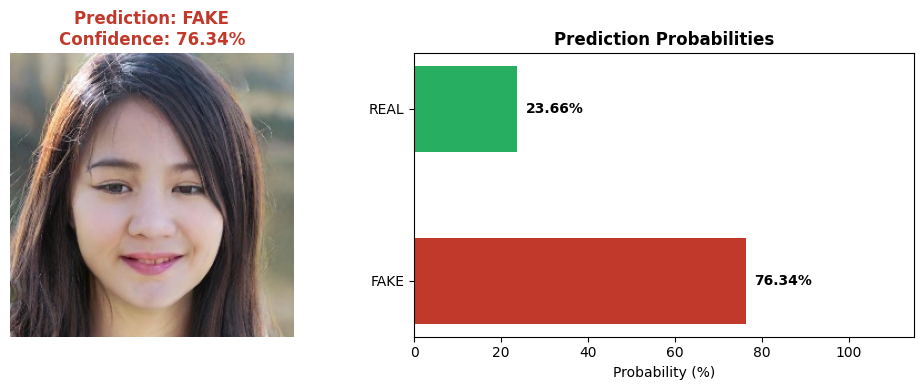


--- Testing Sample REAL Face ---


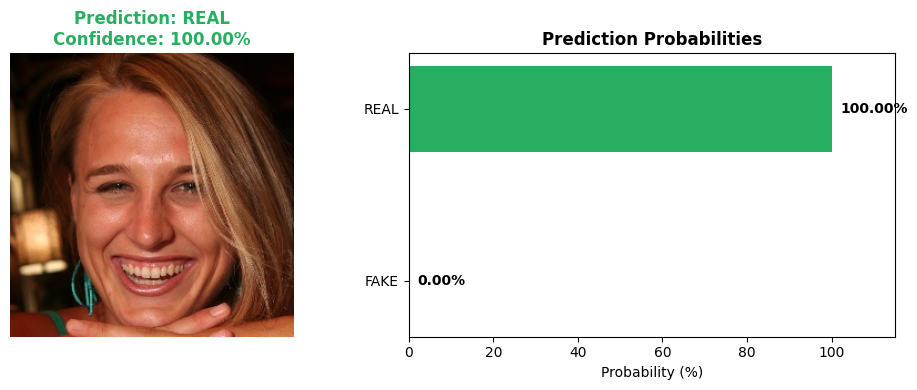

In [6]:
def predict_image(image_path, model, device, class_names=None):
    if class_names is None:
        class_names = ['fake', 'real']
        
    if not os.path.exists(image_path):
        print(f"Image not found at: {image_path}")
        return
        
    image = Image.open(image_path).convert('RGB')
    transform = test_transforms
    input_tensor = transform(image).unsqueeze(0).to(device)
    
    model.eval()
    with torch.no_grad():
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            outputs = model(input_tensor)
            probabilities = torch.softmax(outputs, dim=1)[0]
            confidence, predicted_idx = torch.max(probabilities, 0)
            
    predicted_class = class_names[predicted_idx.item()]
    
    # Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={'width_ratios': [1, 1.2]})
    
    ax1.imshow(image)
    ax1.axis("off")
    title_color = '#27ae60' if predicted_class.lower() == 'real' else '#c0392b'
    ax1.set_title(f"Prediction: {predicted_class.upper()}\nConfidence: {confidence.item()*100:.2f}%", 
                  fontsize=12, fontweight='bold', color=title_color)
    
    # Bar chart of class probabilities
    bar_colors = ['#c0392b' if c.lower() == 'fake' else '#27ae60' for c in class_names]
    prob_values = [probabilities[i].item() * 100 for i in range(len(class_names))]
    bars = ax2.barh([c.upper() for c in class_names], prob_values, color=bar_colors, height=0.5)
    ax2.set_xlim(0, 115)
    ax2.set_xlabel('Probability (%)')
    ax2.set_title('Prediction Probabilities', fontweight='bold')
    
    for bar, val in zip(bars, prob_values):
        ax2.text(val + 2, bar.get_y() + bar.get_height()/2, f"{val:.2f}%", 
                 va='center', fontweight='bold')
                 
    plt.tight_layout()
    plt.show()

# Test sample images from the test set
test_fake_dir = os.path.join(DATASET_PATH, "test", "fake")
test_real_dir = os.path.join(DATASET_PATH, "test", "real")

if os.path.exists(test_fake_dir) and len(os.listdir(test_fake_dir)) > 0:
    sample_fake = os.path.join(test_fake_dir, os.listdir(test_fake_dir)[0])
    print("--- Testing Sample FAKE Face ---")
    predict_image(sample_fake, model, device, class_names)

if os.path.exists(test_real_dir) and len(os.listdir(test_real_dir)) > 0:
    sample_real = os.path.join(test_real_dir, os.listdir(test_real_dir)[0])
    print("\n--- Testing Sample REAL Face ---")
    predict_image(sample_real, model, device, class_names)


## 6. Batch Inference Grid Preview (Sample Test Predictions)
Displays a random sample of test images with True vs Predicted labels, color-coded for fast inspection (Green = Correct, Red = Misclassified).

C:\Users\MADHUSHALNE\AppData\Local\Temp\ipykernel_26840\3201001660.py:22: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


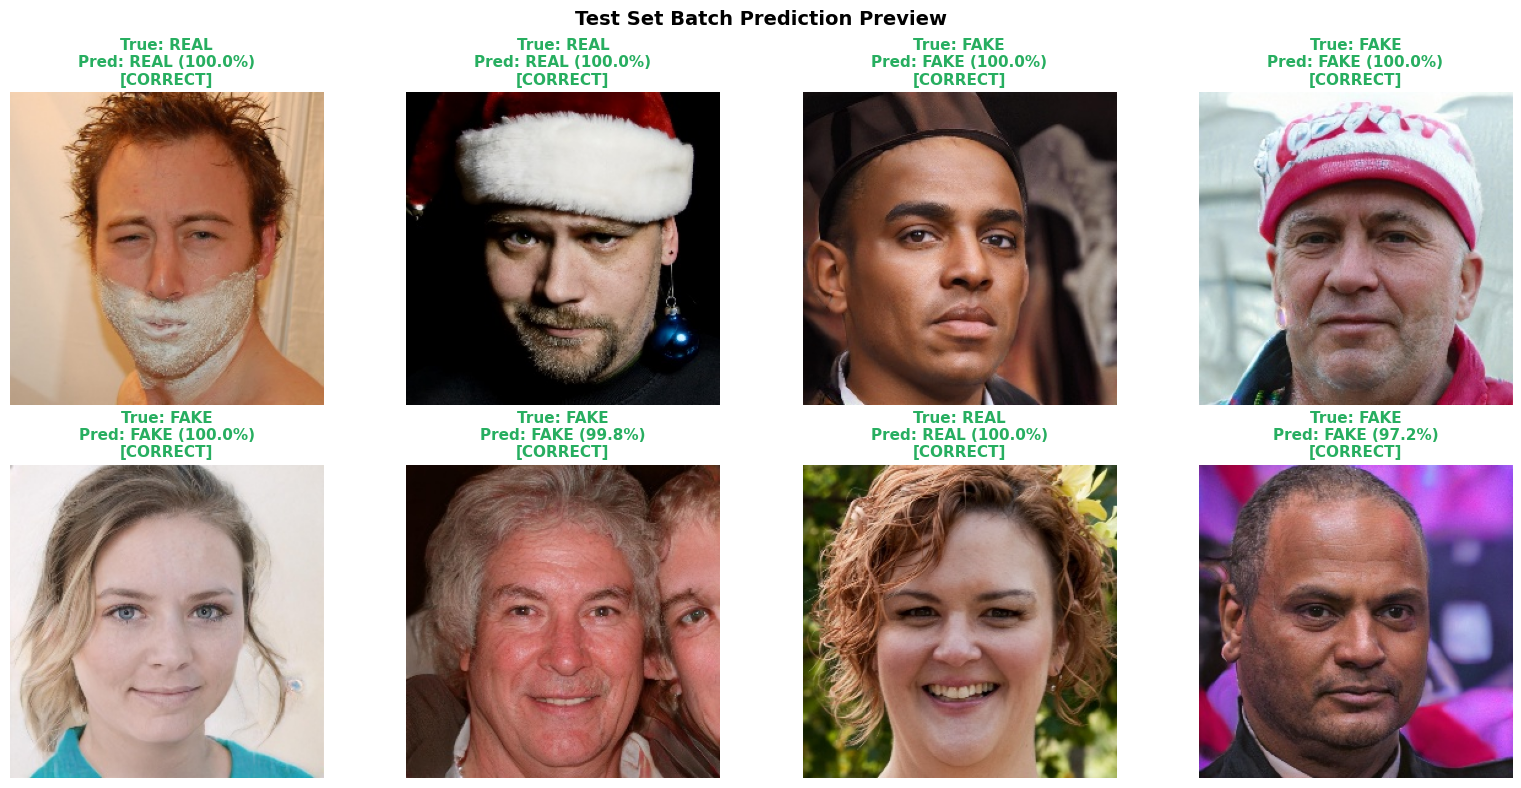

In [7]:
def display_batch_predictions(test_dataset, model, device, class_names, num_samples=8):
    if len(test_dataset) == 0:
        print("[!] Test dataset is empty.")
        return
        
    num_samples = min(num_samples, len(test_dataset))
    indices = np.random.choice(len(test_dataset), size=num_samples, replace=False)
    
    ncols = min(4, num_samples)
    nrows = int(np.ceil(num_samples / ncols))
    
    plt.figure(figsize=(4 * ncols, 4 * nrows))
    for idx, sample_idx in enumerate(indices):
        img_path, true_label_idx = test_dataset.samples[sample_idx]
        true_label = class_names[true_label_idx]
        
        raw_img = Image.open(img_path).convert('RGB')
        tensor = test_transforms(raw_img).unsqueeze(0).to(device)
        
        model.eval()
        with torch.no_grad():
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                output = model(tensor)
                probs = torch.softmax(output, dim=1)[0]
                conf, pred_idx = torch.max(probs, 0)
                pred_label = class_names[pred_idx.item()]
                
        is_correct = (pred_label == true_label)
        status_color = '#27ae60' if is_correct else '#c0392b'
        
        plt.subplot(nrows, ncols, idx + 1)
        plt.imshow(raw_img)
        plt.axis("off")
        plt.title(f"True: {true_label.upper()}\nPred: {pred_label.upper()} ({conf.item()*100:.1f}%)\n[{'CORRECT' if is_correct else 'WRONG'}]", 
                  fontsize=11, fontweight='bold', color=status_color)
                  
    plt.suptitle("Test Set Batch Prediction Preview", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

if len(test_dataset) > 0:
    display_batch_predictions(test_dataset, model, device, class_names, num_samples=8)
